<div style="background-color:#7BAFD4;border-radius:18px;padding:22px 26px;margin-bottom:18px;">
  <div style="font-family:Impact,'Arial Black',Arial,sans-serif;font-size:42px;font-weight:900;letter-spacing:2px;line-height:1;color:white;">GEOG 592</div>
  <div style="font-family:Arial,Helvetica,sans-serif;font-size:22px;font-weight:700;color:#13294B;margin-top:8px;">GIS Programming &middot; Week 10</div>
  <div style="font-family:Arial,Helvetica,sans-serif;font-size:16px;color:#13294B;margin-top:6px;">Automated Atlas: Dams in North Carolina Counties</div>
</div>

**Hailey Rodriguez**

This notebook builds a one-page-per-county atlas of North Carolina. Each page uses a **spatial join** between NC county polygons (U.S. Census Bureau, 2024 cartographic boundaries) and dam locations from the **National Inventory of Dams (NID)**, maintained by the U.S. Army Corps of Engineers. String concatenation turns each join result into a sentence like *"There are 112 dams in Wake County."*

This version is generalized to work for any state. The state and the output file name are set in section 0, and the last cell saves the same code as `dam_atlas.py`, which takes them as command-line arguments.

In [27]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from pathlib import Path

## 0. Choose a state
`STATE` is required. `OUTPUT` is the name of the PDF to save.

In [28]:
STATE = "NC"                 # two-letter state abbreviation
OUTPUT = "Dam_Atlas.pdf"     # name of the PDF to save

state = STATE.upper()

## 1. County polygons

In [29]:
local_county_zip = Path("../week09/cb_2024_us_county_500k.zip")
census_url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip"

counties = gpd.read_file(local_county_zip if local_county_zip.exists() else census_url)

# Chosen state only, alphabetical like the class atlas.
# estimate_utm_crs() picks a projection that fits the state (6543 only works for North Carolina)
state_counties = counties.loc[counties["STUSPS"] == state]
state_counties = (
    state_counties
    .to_crs(state_counties.estimate_utm_crs())
    .sort_values("NAME")
    .reset_index(drop=True)
)
state_name = state_counties["STATE_NAME"].iloc[0]
print(len(state_counties), "counties in", state_name)

100 counties in North Carolina


## 2. Additional vector dataset: dams
The NID publishes the full national inventory as a CSV.

In [30]:
dam_csv = Path("../week10/" + state.lower() + "_dams.csv")
nid_national_url = "https://nid.sec.usace.army.mil/api/nation/csv"

def read_nid_csv(source):
    # Find which of the first few lines holds the real header
    peek = pd.read_csv(source, header=None, nrows=5, low_memory=False)
    header_row = next(i for i, row in peek.iterrows()
                      if row.astype(str).str.strip().eq("Latitude").any())
    return pd.read_csv(source, header=header_row, low_memory=False)

dams_df = read_nid_csv(dam_csv if dam_csv.exists() else nid_national_url)

# If we pulled the national file, keep the chosen state only
dams_df = dams_df[dams_df["State"].astype(str).str.strip().str.upper() == state]

# Make sure coordinates are numbers, not text
dams_df["Latitude"] = pd.to_numeric(dams_df["Latitude"], errors="coerce")
dams_df["Longitude"] = pd.to_numeric(dams_df["Longitude"], errors="coerce")
dams_df = dams_df.dropna(subset=["Latitude", "Longitude"])

# U.S. longitudes are negative (west of Greenwich); fix any missing minus signs
dams_df.loc[dams_df["Longitude"] > 0, "Longitude"] *= -1
print(len(dams_df), "dams with coordinates")

3680 dams with coordinates


CSV → points. Coordinates are lat/long (WGS84, EPSG:4326), then reprojected to match the counties.

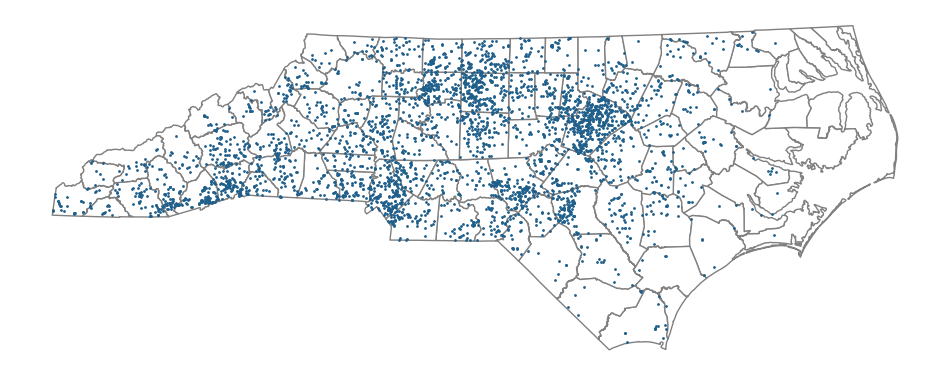

In [31]:
dams = gpd.GeoDataFrame(
    dams_df,
    geometry=gpd.points_from_xy(dams_df["Longitude"], dams_df["Latitude"]),
    crs=4326,
).to_crs(state_counties.crs)

ax = state_counties.plot(edgecolor="gray", facecolor="white", figsize=(12, 5))
dams.plot(ax=ax, markersize=1, color="#1f5f8b")
ax.set_axis_off()

## 3. Spatial join
`gpd.sjoin(..., predicate="within")` tags every dam with the county it sits in. Grouping by county name then gives the number of dams per county. Counties with no dams get a 0 instead of being dropped.

In [32]:
dams_joined = gpd.sjoin(
    dams,
    state_counties[["NAME", "geometry"]],
    how="inner",
    predicate="within",
)

dam_counts = dams_joined.groupby("NAME").size()
state_counties["dam_count"] = state_counties["NAME"].map(dam_counts).fillna(0).astype(int)

state_counties.sort_values("dam_count", ascending=False)[["NAME", "dam_count"]].head(10)

,NAME,dam_count
91,Wake,364
40,Guilford,186
59,Mecklenburg,157
62,Moore,136
33,Forsyth,113
75,Randolph,110
78,Rockingham,93
25,Cumberland,91
44,Henderson,85
48,Iredell,84


Hazard potential is one of the most useful NID fields: it says how bad things would be downstream **if** the dam failed (it is not a rating of the dam's condition). I'll count **High** hazard dams per county for a second sentence.

The CSV stores hazard potential as letter codes (`H`, `S`, `L`), so they get turned into words before counting.

In [33]:
hazard_col = "Hazard Potential Classification"
has_hazard = hazard_col in dams_joined.columns

if has_hazard:
    hazard_names = {"H": "High", "S": "Significant", "L": "Low", "U": "Undetermined"}
    dams_joined["hazard"] = dams_joined[hazard_col].astype(str).str.strip().map(hazard_names).fillna("Undetermined")
    high_counts = dams_joined[dams_joined["hazard"] == "High"].groupby("NAME").size()
    state_counties["high_hazard"] = state_counties["NAME"].map(high_counts).fillna(0).astype(int)
else:
    state_counties["high_hazard"] = 0
    print("No hazard column found, skipping the hazard breakdown")

## 4. Building blocks for each page
These are the class functions, adapted: the county map now shows its dams, and the info panel writes the spatial join result as a sentence.

In [34]:
COUNTY_FILL = "#dfe9e4"
DAM_COLOR = "#1f5f8b"
HAZARD_COLORS = {"High": "#b5413a", "Significant": "#e39b3b",
                 "Low": "#7b9b90", "Undetermined": "#bbbbbb"}

def county_map(county, ax):
    selected = state_counties[state_counties["NAME"] == county]
    selected.plot(ax=ax, edgecolor="black", facecolor=COUNTY_FILL)
    county_dams = dams_joined[dams_joined["NAME"] == county]
    if len(county_dams) > 0:
        county_dams.plot(ax=ax, color=DAM_COLOR, markersize=18,
                         marker="^", edgecolor="white", linewidth=0.4)
    ax.set_axis_off()


def locator_map(county, ax):
    selected = state_counties[state_counties["NAME"] == county]
    state_counties.plot(ax=ax, edgecolor="gray", facecolor="white", linewidth=0.3)
    selected.plot(ax=ax, edgecolor="black", facecolor=DAM_COLOR)
    ax.set_axis_off()

In [35]:
def dam_sentence(county):
    row = state_counties.loc[state_counties["NAME"] == county].iloc[0]
    n = row["dam_count"]

    # String concatenation, with grammar that changes for 0 / 1 / many
    if n == 0:
        phrase = "There are no inventoried dams in " + county + " County."
    elif n == 1:
        phrase = "There is 1 dam in " + county + " County."
    else:
        phrase = "There are " + str(n) + " dams in " + county + " County."

    if has_hazard and n > 0:
        h = row["high_hazard"]
        phrase += "\n\n" + str(h) + " of " + ("it is" if n == 1 else "them are") + \
                  " classified as High hazard potential."
    return phrase


def county_info(county, ax):
    row = state_counties.loc[state_counties["NAME"] == county].iloc[0]
    ax.text(0.0, 0.95, str(row["dam_count"]), transform=ax.transAxes,
            fontsize=54, fontweight="bold", color=DAM_COLOR, va="top")
    ax.text(0.0, 0.50, dam_sentence(county), transform=ax.transAxes,
            fontsize=13, va="top", wrap=True)
    ax.set_axis_off()


def hazard_bar(county, ax):
    county_dams = dams_joined[dams_joined["NAME"] == county]
    if not has_hazard or len(county_dams) == 0:
        ax.set_axis_off()
        return
    order = [k for k in HAZARD_COLORS if k in county_dams["hazard"].unique()]
    counts = county_dams["hazard"].value_counts().reindex(order)
    ax.barh(counts.index, counts.values, color=[HAZARD_COLORS[k] for k in order])
    ax.invert_yaxis()
    for i, v in enumerate(counts.values):
        ax.text(v, i, " " + str(v), va="center", fontsize=10)
    ax.set_title("Dams by hazard potential", fontsize=11, loc="left")
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.set_xticks([])

Test it on one county before looping.

In [36]:
print(dam_sentence("Orange"))
print()
print(dam_sentence("Wake"))

There are 43 dams in Orange County.

23 of them are classified as High hazard potential.

There are 364 dams in Wake County.

208 of them are classified as High hazard potential.


## 5. Page layout
Same `fig.add_axes` layout from class, with the hazard bar chart in place of the land/water pie.

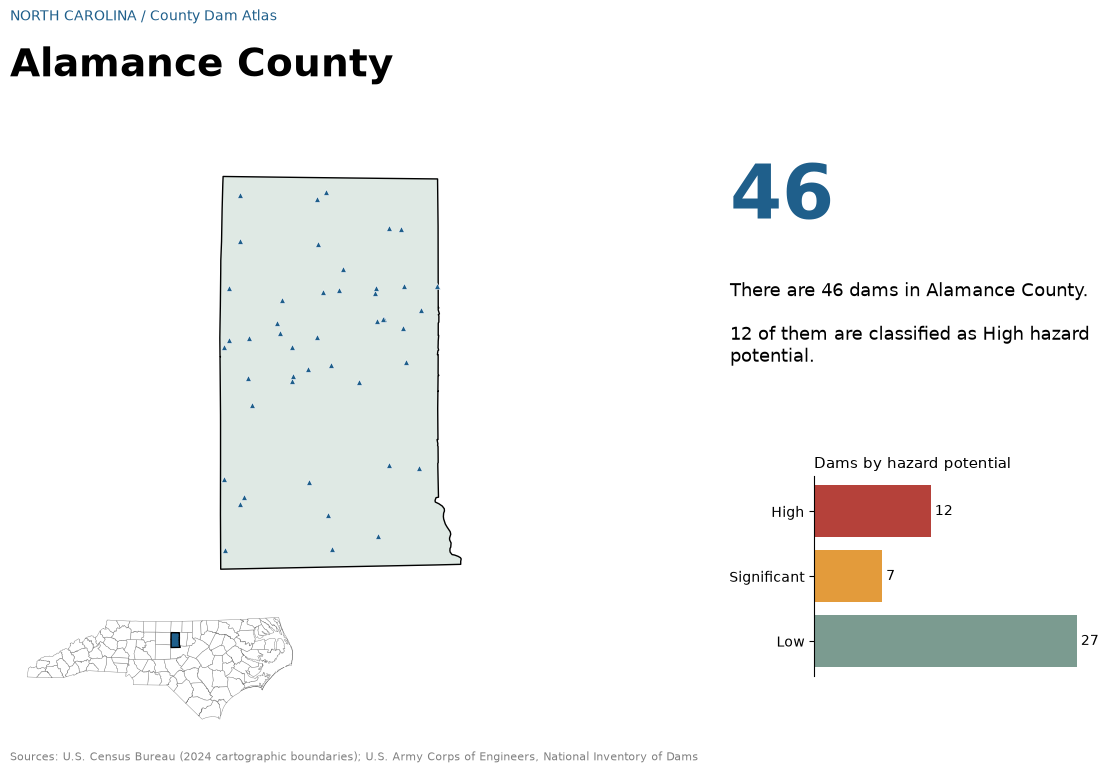

In [37]:
def county_figure(county, pdf=None):
    fig = plt.figure(figsize=(12, 8))

    # [left, bottom, width, height] as fractions of the figure
    ax_county = fig.add_axes([0.05, 0.23, 0.55, 0.54])
    ax_locator = fig.add_axes([0.05, 0.06, 0.25, 0.14])
    ax_info = fig.add_axes([0.65, 0.45, 0.30, 0.33])
    ax_bar = fig.add_axes([0.72, 0.12, 0.23, 0.25])

    county_map(county, ax_county)
    locator_map(county, ax_locator)
    county_info(county, ax_info)
    hazard_bar(county, ax_bar)

    fig.text(0.05, 0.94, state_name.upper() + " / County Dam Atlas", fontsize=10, color=DAM_COLOR)
    fig.text(0.05, 0.87, county + " County", fontsize=28, fontweight="bold")
    fig.text(0.05, 0.015,
             "Sources: U.S. Census Bureau (2024 cartographic boundaries); "
             "U.S. Army Corps of Engineers, National Inventory of Dams",
             fontsize=8, color="gray")

    if pdf is None:
        plt.show()
    else:
        pdf.savefig(fig, dpi=50)
        plt.close(fig)

county_figure(state_counties["NAME"].iloc[0])

## 6. Build the full atlas
One page per county, alphabetical. This takes a minute.

In [38]:
with PdfPages(OUTPUT) as pdf:
    for county in state_counties["NAME"]:
        county_figure(county, pdf)

print("Atlas size:", round(Path(OUTPUT).stat().st_size / 1e6, 1), "MB")

Atlas size: 33.6 MB


## 7. Two sample pages for GitHub
The assignment asks for two pages, not the whole atlas (unless it's under 50 MB). This saves Orange and Wake as a separate 2-page PDF.

In [39]:
with PdfPages("NC_Dam_Atlas_sample_pages.pdf") as pdf:
    for county in ["Orange", "Wake"]:
        county_figure(county, pdf)

## Turning this into a Python script

This notebook uses `STATE` and `OUTPUT` variables in section 0, because `argparse` doesn't work inside a notebook. The script version swaps those two variables for command-line arguments, so I wrote it out with `dam_csv` in the last cell instead of converting the whole notebook. That cell saves `dam_atlas.py` into the `weeok11` folder. Then I went into that folder in the terminal and ran `python dam_atlas.py NC` to make sure it works on its own, and it spits out the same county dam atlas as `Dam_Atlas.pdf`. The state is required, and the output name is optional, so `python dam_atlas.py NC NC_Dam_Atlas.pdf` saves it under a different name.

In [ ]:
%pip install nbconvert
#get_ipython().run_line_magic('pip', 'install nbconvert')
#python3 -m nbconvert --to script damn_atlas_refactored.ipynb

Note: you may need to restart the kernel to use updated packages.


In [41]:
!jupyter nbconvert --to script damn_atlas_refactored.ipynb

[NbConvertApp] Converting notebook damn_atlas_refactored.ipynb to script
[NbConvertApp] Writing 11560 bytes to damn_atlas_refactored.py


### Notes
- The NID only includes dams that meet federal criteria (mostly by height, storage, or hazard), so a county showing 0 may still have small dams that aren't in the inventory.
- Hazard potential describes the consequences downstream if a dam failed. It is **not** a measure of the dam's condition or how likely it is to fail.